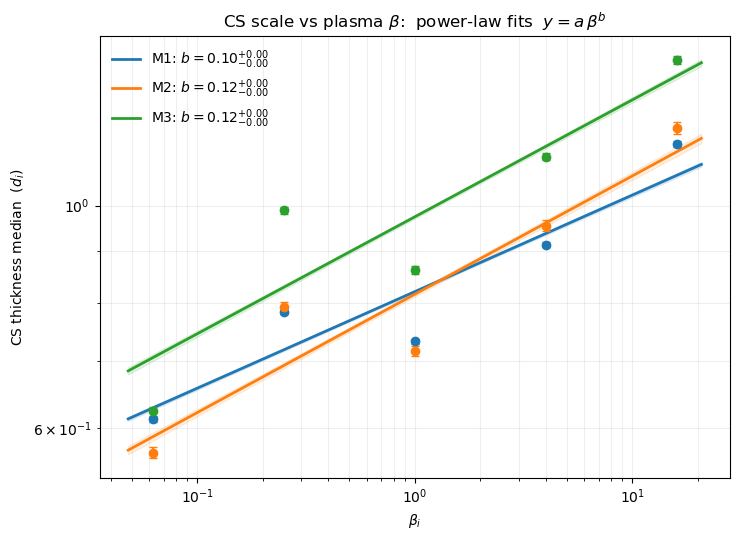


method         a       b    b_se            b 68% CI  chi2_red  weighted   n
----------------------------------------------------------------------------
M1        0.8205   0.096   0.001      [0.095, 0.098]    297.66      True   5
M2        0.8156   0.118   0.003      [0.115, 0.121]     95.60      True   5
M3        0.9746   0.117   0.002      [0.115, 0.119]    248.93      True   5

Figure -> cs_scale_vs_beta_methods.png
Table  -> powerlaw_fits_by_method.csv


In [1]:
# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")
import os, csv
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

# ======================================================================
# SETTINGS
# ======================================================================
CSV_PATH  = str(RESULTS / "cs_thickness_pooled_1/pooled_summary.csv")   # output of the pooling script
VALUE_COL = "median_lognorm_di"     # per-(beta,method) value to fit
ERR_COL   = "median_se_di"          # 1-sigma on the value; set "" to force unweighted
METHODS   = ["M1", "M2", "M3"]
YLABEL    = r"CS thickness median  $(d_i)$"   # relabel if you fit a different quantity
SHOW_BANDS = True
N_MC       = 10000
OUT_FIG    = str(RESULTS / "cs_scale_vs_beta_methods.png")
OUT_TABLE  = str(RESULTS / "powerlaw_fits_by_method.csv")
COLORS     = {"M1": "C0", "M2": "C1", "M3": "C2"}

# ======================================================================
# READ pooled_summary.csv  ->  {method: {beta, y, sy}}
# ======================================================================
data = defaultdict(lambda: {"beta": [], "y": [], "sy": []})
with open(CSV_PATH) as f:
    for row in csv.DictReader(f):
        m = row.get("method")
        if m not in METHODS:
            continue
        try:
            beta = float(row["beta"]); y = float(row[VALUE_COL])
        except (KeyError, ValueError):
            continue
        if not np.isfinite(y) or y <= 0:
            continue
        sy = np.nan
        if ERR_COL and row.get(ERR_COL, "") not in ("", "nan", "NaN"):
            try:
                sy = float(row[ERR_COL])
            except ValueError:
                sy = np.nan
        data[m]["beta"].append(beta); data[m]["y"].append(y); data[m]["sy"].append(sy)


# ======================================================================
# Weighted power-law fit (c = 0)  +  Monte-Carlo exponent/band
#   log y = log a + b log beta ; weight 1/sigma_logy with sigma_logy = sy/y.
#   If any SE is missing, falls back to an unweighted (residual-based) fit.
# ======================================================================
def fit_powerlaw(beta, y, sy, xgrid, n_mc=N_MC, rng=None):
    beta, y, sy = map(lambda v: np.asarray(v, float), (beta, y, sy))
    order = np.argsort(beta)
    beta, y, sy = beta[order], y[order], sy[order]
    logx, logy = np.log(beta), np.log(y)
    n = len(beta); dof = max(n - 2, 1)
    rng = rng or np.random.default_rng(0)

    weighted = np.all(np.isfinite(sy)) and np.all(sy > 0)
    if weighted:
        sig_ly = sy / y
        w = 1.0 / sig_ly
        coeffs, cov = np.polyfit(logx, logy, 1, w=w, cov="unscaled")
    else:
        w = None
        coeffs, cov = np.polyfit(logx, logy, 1, cov=True)   # residual-based errors

    b, log_a = coeffs
    a = float(np.exp(log_a))
    b_se = float(np.sqrt(cov[0, 0]))
    resid = logy - (log_a + b * logx)

    if weighted:
        noise = sig_ly
        chi2_red = float(np.sum((resid / sig_ly) ** 2) / dof)
    else:
        noise = np.full(n, np.sqrt(np.sum(resid ** 2) / dof))
        chi2_red = np.nan   # not meaningful when sigma is estimated from residuals

    bs = np.empty(n_mc)
    curves = np.empty((n_mc, xgrid.size))
    for i in range(n_mc):
        logy_i = logy + rng.normal(0.0, noise)
        if weighted:
            bi, log_ai = np.polyfit(logx, logy_i, 1, w=w)
        else:
            bi, log_ai = np.polyfit(logx, logy_i, 1)
        bs[i] = bi
        curves[i] = np.exp(log_ai) * xgrid ** bi
    b_med = float(np.median(bs)); b_lo, b_hi = np.percentile(bs, [16, 84])
    band_lo, band_hi = np.percentile(curves, [16, 84], axis=0)

    return {"a": a, "b": float(b), "b_se": b_se, "b_med": b_med,
            "b_lo": float(b_lo), "b_hi": float(b_hi), "chi2_red": chi2_red,
            "weighted": bool(weighted), "n": n, "beta": beta, "y": y, "sy": sy,
            "band_lo": band_lo, "band_hi": band_hi}


# ======================================================================
# Fit each method + overlay on one log-log axis
# ======================================================================
all_beta = np.array([b for m in METHODS for b in data[m]["beta"]], float)
if all_beta.size == 0:
    raise SystemExit(f"No usable rows found in {CSV_PATH} for methods {METHODS}.")
xgrid = np.logspace(np.log10(all_beta.min() / 1.3), np.log10(all_beta.max() * 1.3), 200)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
fits = {}
for m in METHODS:
    d = data[m]
    if len(d["beta"]) < 3:
        print(f"{m}: only {len(d['beta'])} point(s) -> skipping (need >=3 for a power law)")
        continue
    res = fit_powerlaw(d["beta"], d["y"], d["sy"], xgrid)
    fits[m] = res
    c = COLORS.get(m)
    if SHOW_BANDS:
        ax.fill_between(xgrid, res["band_lo"], res["band_hi"], color=c, alpha=0.12)
    ax.plot(xgrid, res["a"] * xgrid ** res["b"], "-", color=c, lw=2,
            label=fr"{m}: $b={res['b_med']:.2f}^{{+{res['b_hi']-res['b_med']:.2f}}}_{{-{res['b_med']-res['b_lo']:.2f}}}$")
    if np.all(np.isfinite(res["sy"])):
        ax.errorbar(res["beta"], res["y"], yerr=res["sy"], fmt="o", color=c,
                    ms=6, capsize=3, lw=1.4)
    else:
        ax.plot(res["beta"], res["y"], "o", color=c, ms=6)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$\beta_i$")
ax.set_ylabel(YLABEL)
ax.set_title(r"CS scale vs plasma $\beta$:  power-law fits  $y = a\,\beta^{b}$")
ax.legend(frameon=False)
ax.grid(True, which="both", alpha=0.2)
fig.tight_layout()
fig.savefig(OUT_FIG, dpi=300)
plt.show()

# ======================================================================
# Comparison table  (printed + CSV)
# ======================================================================
print(f"\n{'method':<7}{'a':>9}{'b':>8}{'b_se':>8}{'b 68% CI':>20}{'chi2_red':>10}{'weighted':>10}{'n':>4}")
print("-" * 76)
for m in METHODS:
    if m not in fits:
        continue
    r = fits[m]
    ci = f"[{r['b_lo']:.3f}, {r['b_hi']:.3f}]"
    chi = "  n/a" if not np.isfinite(r["chi2_red"]) else f"{r['chi2_red']:.2f}"
    print(f"{m:<7}{r['a']:>9.4f}{r['b_med']:>8.3f}{r['b_se']:>8.3f}{ci:>20}{chi:>10}{str(r['weighted']):>10}{r['n']:>4}")

with open(OUT_TABLE, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["method", "a", "b", "b_se", "b_ci_lo", "b_ci_hi", "chi2_red", "weighted", "n_points"])
    for m in METHODS:
        if m not in fits:
            continue
        r = fits[m]
        w.writerow([m, r["a"], r["b_med"], r["b_se"], r["b_lo"], r["b_hi"],
                    r["chi2_red"], r["weighted"], r["n"]])

print(f"\nFigure -> {OUT_FIG}\nTable  -> {OUT_TABLE}")

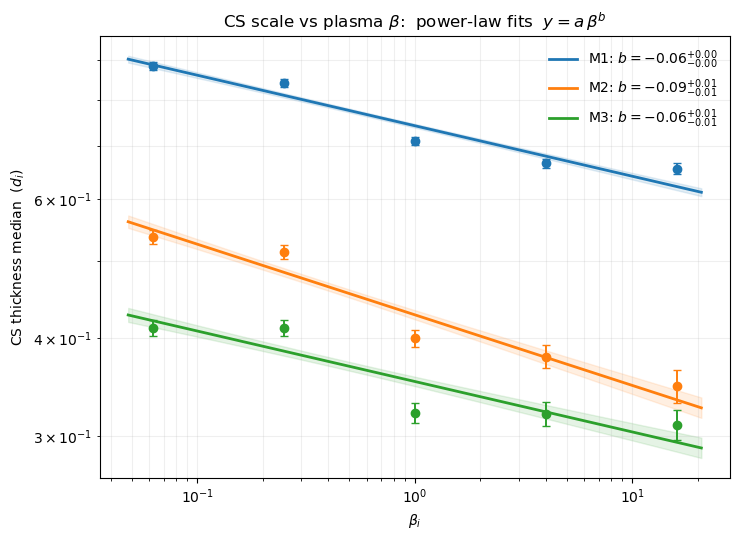


method         a       b    b_se            b 68% CI  chi2_red  weighted   n
----------------------------------------------------------------------------
M1        0.7428  -0.064   0.003    [-0.067, -0.061]     13.34      True   5
M2        0.4278  -0.089   0.007    [-0.096, -0.083]      5.66      True   5
M3        0.3522  -0.064   0.007    [-0.071, -0.057]      6.77      True   5

Figure -> cs_scale_vs_beta_methods.png
Table  -> powerlaw_fits_by_method.csv


In [1]:
import os, csv
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

# ======================================================================
# SETTINGS
# ======================================================================
CSV_PATH  = str(RESULTS / "cs_thickness_pooled/pooled_summary.csv")   # output of the pooling script
VALUE_COL = "median_lognorm_di"     # per-(beta,method) value to fit
ERR_COL   = "median_se_di"          # 1-sigma on the value; set "" to force unweighted
METHODS   = ["M1", "M2", "M3"]
YLABEL    = r"CS thickness median  $(d_i)$"   # relabel if you fit a different quantity
SHOW_BANDS = True
N_MC       = 10000
OUT_FIG    = str(RESULTS / "cs_scale_vs_beta_methods.png")
OUT_TABLE  = str(RESULTS / "powerlaw_fits_by_method.csv")
COLORS     = {"M1": "C0", "M2": "C1", "M3": "C2"}

# ======================================================================
# READ pooled_summary.csv  ->  {method: {beta, y, sy}}
# ======================================================================
data = defaultdict(lambda: {"beta": [], "y": [], "sy": []})
with open(CSV_PATH) as f:
    for row in csv.DictReader(f):
        m = row.get("method")
        if m not in METHODS:
            continue
        try:
            beta = float(row["beta"]); y = float(row[VALUE_COL])
        except (KeyError, ValueError):
            continue
        if not np.isfinite(y) or y <= 0:
            continue
        sy = np.nan
        if ERR_COL and row.get(ERR_COL, "") not in ("", "nan", "NaN"):
            try:
                sy = float(row[ERR_COL])
            except ValueError:
                sy = np.nan
        data[m]["beta"].append(beta); data[m]["y"].append(y); data[m]["sy"].append(sy)


# ======================================================================
# Weighted power-law fit (c = 0)  +  Monte-Carlo exponent/band
#   log y = log a + b log beta ; weight 1/sigma_logy with sigma_logy = sy/y.
#   If any SE is missing, falls back to an unweighted (residual-based) fit.
# ======================================================================
def fit_powerlaw(beta, y, sy, xgrid, n_mc=N_MC, rng=None):
    beta, y, sy = map(lambda v: np.asarray(v, float), (beta, y, sy))
    order = np.argsort(beta)
    beta, y, sy = beta[order], y[order], sy[order]
    logx, logy = np.log(beta), np.log(y)
    n = len(beta); dof = max(n - 2, 1)
    rng = rng or np.random.default_rng(0)

    weighted = np.all(np.isfinite(sy)) and np.all(sy > 0)
    if weighted:
        sig_ly = sy / y
        w = 1.0 / sig_ly
        coeffs, cov = np.polyfit(logx, logy, 1, w=w, cov="unscaled")
    else:
        w = None
        coeffs, cov = np.polyfit(logx, logy, 1, cov=True)   # residual-based errors

    b, log_a = coeffs
    a = float(np.exp(log_a))
    b_se = float(np.sqrt(cov[0, 0]))
    resid = logy - (log_a + b * logx)

    if weighted:
        noise = sig_ly
        chi2_red = float(np.sum((resid / sig_ly) ** 2) / dof)
    else:
        noise = np.full(n, np.sqrt(np.sum(resid ** 2) / dof))
        chi2_red = np.nan   # not meaningful when sigma is estimated from residuals

    bs = np.empty(n_mc)
    curves = np.empty((n_mc, xgrid.size))
    for i in range(n_mc):
        logy_i = logy + rng.normal(0.0, noise)
        if weighted:
            bi, log_ai = np.polyfit(logx, logy_i, 1, w=w)
        else:
            bi, log_ai = np.polyfit(logx, logy_i, 1)
        bs[i] = bi
        curves[i] = np.exp(log_ai) * xgrid ** bi
    b_med = float(np.median(bs)); b_lo, b_hi = np.percentile(bs, [16, 84])
    band_lo, band_hi = np.percentile(curves, [16, 84], axis=0)

    return {"a": a, "b": float(b), "b_se": b_se, "b_med": b_med,
            "b_lo": float(b_lo), "b_hi": float(b_hi), "chi2_red": chi2_red,
            "weighted": bool(weighted), "n": n, "beta": beta, "y": y, "sy": sy,
            "band_lo": band_lo, "band_hi": band_hi}


# ======================================================================
# Fit each method + overlay on one log-log axis
# ======================================================================
all_beta = np.array([b for m in METHODS for b in data[m]["beta"]], float)
if all_beta.size == 0:
    raise SystemExit(f"No usable rows found in {CSV_PATH} for methods {METHODS}.")
xgrid = np.logspace(np.log10(all_beta.min() / 1.3), np.log10(all_beta.max() * 1.3), 200)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
fits = {}
for m in METHODS:
    d = data[m]
    if len(d["beta"]) < 3:
        print(f"{m}: only {len(d['beta'])} point(s) -> skipping (need >=3 for a power law)")
        continue
    res = fit_powerlaw(d["beta"], d["y"], d["sy"], xgrid)
    fits[m] = res
    c = COLORS.get(m)
    if SHOW_BANDS:
        ax.fill_between(xgrid, res["band_lo"], res["band_hi"], color=c, alpha=0.12)
    ax.plot(xgrid, res["a"] * xgrid ** res["b"], "-", color=c, lw=2,
            label=fr"{m}: $b={res['b_med']:.2f}^{{+{res['b_hi']-res['b_med']:.2f}}}_{{-{res['b_med']-res['b_lo']:.2f}}}$")
    if np.all(np.isfinite(res["sy"])):
        ax.errorbar(res["beta"], res["y"], yerr=res["sy"], fmt="o", color=c,
                    ms=6, capsize=3, lw=1.4)
    else:
        ax.plot(res["beta"], res["y"], "o", color=c, ms=6)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$\beta_i$")
ax.set_ylabel(YLABEL)
ax.set_title(r"CS scale vs plasma $\beta$:  power-law fits  $y = a\,\beta^{b}$")
ax.legend(frameon=False)
ax.grid(True, which="both", alpha=0.2)
fig.tight_layout()
fig.savefig(OUT_FIG, dpi=300)
plt.show()

# ======================================================================
# Comparison table  (printed + CSV)
# ======================================================================
print(f"\n{'method':<7}{'a':>9}{'b':>8}{'b_se':>8}{'b 68% CI':>20}{'chi2_red':>10}{'weighted':>10}{'n':>4}")
print("-" * 76)
for m in METHODS:
    if m not in fits:
        continue
    r = fits[m]
    ci = f"[{r['b_lo']:.3f}, {r['b_hi']:.3f}]"
    chi = "  n/a" if not np.isfinite(r["chi2_red"]) else f"{r['chi2_red']:.2f}"
    print(f"{m:<7}{r['a']:>9.4f}{r['b_med']:>8.3f}{r['b_se']:>8.3f}{ci:>20}{chi:>10}{str(r['weighted']):>10}{r['n']:>4}")

with open(OUT_TABLE, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["method", "a", "b", "b_se", "b_ci_lo", "b_ci_hi", "chi2_red", "weighted", "n_points"])
    for m in METHODS:
        if m not in fits:
            continue
        r = fits[m]
        w.writerow([m, r["a"], r["b_med"], r["b_se"], r["b_lo"], r["b_hi"],
                    r["chi2_red"], r["weighted"], r["n"]])

print(f"\nFigure -> {OUT_FIG}\nTable  -> {OUT_TABLE}")

In [5]:
import csv
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

# ======================================================================
# SETTINGS
# ======================================================================
# Two pooled_summary.csv files, same format as before (columns include
# beta, method, VALUE_COL, ERR_COL). In each file the "beta" column is the
# parameter being SCANNED in that panel.
CSV1_PATH = str(RESULTS / "cs_thickness_pooled_1/pooled_summary.csv")     # LEFT  panel: proton/ion beta scan (beta_e = 1 fixed)
CSV2_PATH = str(RESULTS / "cs_thickness_pooled/pooled_summary.csv")     # RIGHT panel: electron beta scan   (beta_p = 1 fixed)

VALUE_COL = "median_lognorm_di"     # per-(beta,method) value to fit  ->  lambda
ERR_COL   = "median_se_di"          # 1-sigma on the value; set "" to force unweighted
METHODS   = ["M1", "M2", "M3"]
YLABEL    = r"CS thickness  $\lambda$  $(d_i)$"
SHOW_BANDS = True
SHAREY     = True        # True -> identical y-axis on both (fairer flat-vs-sloped view)
N_MC       = 10000
OUT_FIG    = str(RESULTS / "cs_lambda_vs_beta_two_panels.png")
OUT_TABLE  = str(RESULTS / "powerlaw_fits_by_method.csv")

# method colours (match the thickness-comparison figure)
COLORS = {"M1": "#0072B2", "M2": "#E69F00", "M3": "#009E73"}

# per-panel headings / axis labels
LEFT_TITLE   = r"$\beta_e = 1$"     # left: electron beta held fixed
RIGHT_TITLE  = r"$\beta_p = 1$"     # right: proton beta held fixed
LEFT_XLABEL  = r"$\beta_i$"         # left x-axis: ion (proton) beta varies
RIGHT_XLABEL = r"$\beta_e$"         # right x-axis: electron beta varies
SUPTITLE     = r"CS thickness power-law fits:   $\lambda = a\,\beta^{\,b}$"


# ======================================================================
# READ a pooled_summary.csv  ->  {method: {beta, y, sy}}
# ======================================================================
def read_summary(csv_path):
    data = defaultdict(lambda: {"beta": [], "y": [], "sy": []})
    with open(csv_path) as f:
        for row in csv.DictReader(f):
            m = row.get("method")
            if m not in METHODS:
                continue
            try:
                beta = float(row["beta"]); y = float(row[VALUE_COL])
            except (KeyError, ValueError):
                continue
            if not np.isfinite(y) or y <= 0:
                continue
            sy = np.nan
            if ERR_COL and row.get(ERR_COL, "") not in ("", "nan", "NaN"):
                try:
                    sy = float(row[ERR_COL])
                except ValueError:
                    sy = np.nan
            data[m]["beta"].append(beta); data[m]["y"].append(y); data[m]["sy"].append(sy)
    return data


# ======================================================================
# Weighted power-law fit (c = 0)  +  Monte-Carlo exponent/band
#   log y = log a + b log beta ; weight 1/sigma_logy with sigma_logy = sy/y.
#   If any SE is missing, falls back to an unweighted (residual-based) fit.
# ======================================================================
def fit_powerlaw(beta, y, sy, xgrid, n_mc=N_MC, rng=None):
    beta, y, sy = map(lambda v: np.asarray(v, float), (beta, y, sy))
    order = np.argsort(beta)
    beta, y, sy = beta[order], y[order], sy[order]
    logx, logy = np.log(beta), np.log(y)
    n = len(beta); dof = max(n - 2, 1)
    rng = rng or np.random.default_rng(0)

    weighted = np.all(np.isfinite(sy)) and np.all(sy > 0)
    if weighted:
        sig_ly = sy / y
        w = 1.0 / sig_ly
        coeffs, cov = np.polyfit(logx, logy, 1, w=w, cov="unscaled")
    else:
        w = None
        coeffs, cov = np.polyfit(logx, logy, 1, cov=True)   # residual-based errors

    b, log_a = coeffs
    a = float(np.exp(log_a))
    b_se = float(np.sqrt(cov[0, 0]))
    resid = logy - (log_a + b * logx)

    if weighted:
        noise = sig_ly
        chi2_red = float(np.sum((resid / sig_ly) ** 2) / dof)
    else:
        noise = np.full(n, np.sqrt(np.sum(resid ** 2) / dof))
        chi2_red = np.nan   # not meaningful when sigma is estimated from residuals

    bs = np.empty(n_mc)
    curves = np.empty((n_mc, xgrid.size))
    for i in range(n_mc):
        logy_i = logy + rng.normal(0.0, noise)
        if weighted:
            bi, log_ai = np.polyfit(logx, logy_i, 1, w=w)
        else:
            bi, log_ai = np.polyfit(logx, logy_i, 1)
        bs[i] = bi
        curves[i] = np.exp(log_ai) * xgrid ** bi
    b_med = float(np.median(bs)); b_lo, b_hi = np.percentile(bs, [16, 84])
    band_lo, band_hi = np.percentile(curves, [16, 84], axis=0)

    return {"a": a, "b": float(b), "b_se": b_se, "b_med": b_med,
            "b_lo": float(b_lo), "b_hi": float(b_hi), "chi2_red": chi2_red,
            "weighted": bool(weighted), "n": n, "beta": beta, "y": y, "sy": sy,
            "band_lo": band_lo, "band_hi": band_hi}


# ======================================================================
# Fit every method for one CSV and draw it on one axis
# ======================================================================
def plot_panel(ax, data, xgrid, title, xlabel, ylabel=None):
    fits = {}
    for m in METHODS:
        d = data[m]
        if len(d["beta"]) < 3:
            print(f"[{title}] {m}: only {len(d['beta'])} point(s) -> skipping (need >=3)")
            continue
        res = fit_powerlaw(d["beta"], d["y"], d["sy"], xgrid)
        fits[m] = res
        c = COLORS.get(m)
        if SHOW_BANDS:
            ax.fill_between(xgrid, res["band_lo"], res["band_hi"], color=c, alpha=0.12)
        ax.plot(xgrid, res["a"] * xgrid ** res["b"], "-", color=c, lw=2,
                label=fr"{m}: $b={res['b_med']:.2f}^{{+{res['b_hi']-res['b_med']:.2f}}}_{{-{res['b_med']-res['b_lo']:.2f}}}$")
        if np.all(np.isfinite(res["sy"])):
            ax.errorbar(res["beta"], res["y"], yerr=res["sy"], fmt="o", color=c,
                        ms=6, capsize=3, lw=1.4)
        else:
            ax.plot(res["beta"], res["y"], "o", color=c, ms=6)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(xgrid.min(), xgrid.max())     # same x-range on both panels
    ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False)
    ax.grid(True, which="both", alpha=0.2)
    return fits


# ======================================================================
# MAIN
# ======================================================================
data_L = read_summary(CSV1_PATH)
data_R = read_summary(CSV2_PATH)

# common x-range from BOTH files -> identical x-axis extent on both panels
all_beta = np.array([b for d in (data_L, data_R) for m in METHODS for b in d[m]["beta"]], float)
if all_beta.size == 0:
    raise SystemExit("No usable rows found in either CSV (check paths / columns).")
xgrid = np.logspace(np.log10(all_beta.min() / 1.3), np.log10(all_beta.max() * 1.3), 200)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=SHAREY)
fits_L = plot_panel(axL, data_L, xgrid, LEFT_TITLE,  LEFT_XLABEL,  ylabel=YLABEL)
fits_R = plot_panel(axR, data_R, xgrid, RIGHT_TITLE, RIGHT_XLABEL,
                    ylabel=(None if SHAREY else YLABEL))

fig.suptitle(SUPTITLE, y=1.00)
fig.tight_layout()
fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# Comparison table  (printed + CSV, both scans)
# ======================================================================
def emit(fits, scan_label, writer):
    print(f"\n=== {scan_label} ===")
    print(f"{'method':<7}{'a':>9}{'b':>8}{'b_se':>8}{'b 68% CI':>20}{'chi2_red':>10}{'weighted':>10}{'n':>4}")
    print("-" * 76)
    for m in METHODS:
        if m not in fits:
            continue
        r = fits[m]
        ci = f"[{r['b_lo']:.3f}, {r['b_hi']:.3f}]"
        chi = "  n/a" if not np.isfinite(r["chi2_red"]) else f"{r['chi2_red']:.2f}"
        print(f"{m:<7}{r['a']:>9.4f}{r['b_med']:>8.3f}{r['b_se']:>8.3f}{ci:>20}{chi:>10}{str(r['weighted']):>10}{r['n']:>4}")
        writer.writerow([scan_label, m, r["a"], r["b_med"], r["b_se"], r["b_lo"], r["b_hi"],
                         r["chi2_red"], r["weighted"], r["n"]])

with open(OUT_TABLE, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["scan", "method", "a", "b", "b_se", "b_ci_lo", "b_ci_hi", "chi2_red", "weighted", "n_points"])
    emit(fits_L, "beta_i scan (CSV1, beta_e=1)", w)
    emit(fits_R, "beta_e scan (CSV2, beta_p=1)", w)

print(f"\nFigure -> {OUT_FIG}\nTable  -> {OUT_TABLE}")

FileNotFoundError: [Errno 2] No such file or directory: 'CSV1.csv'

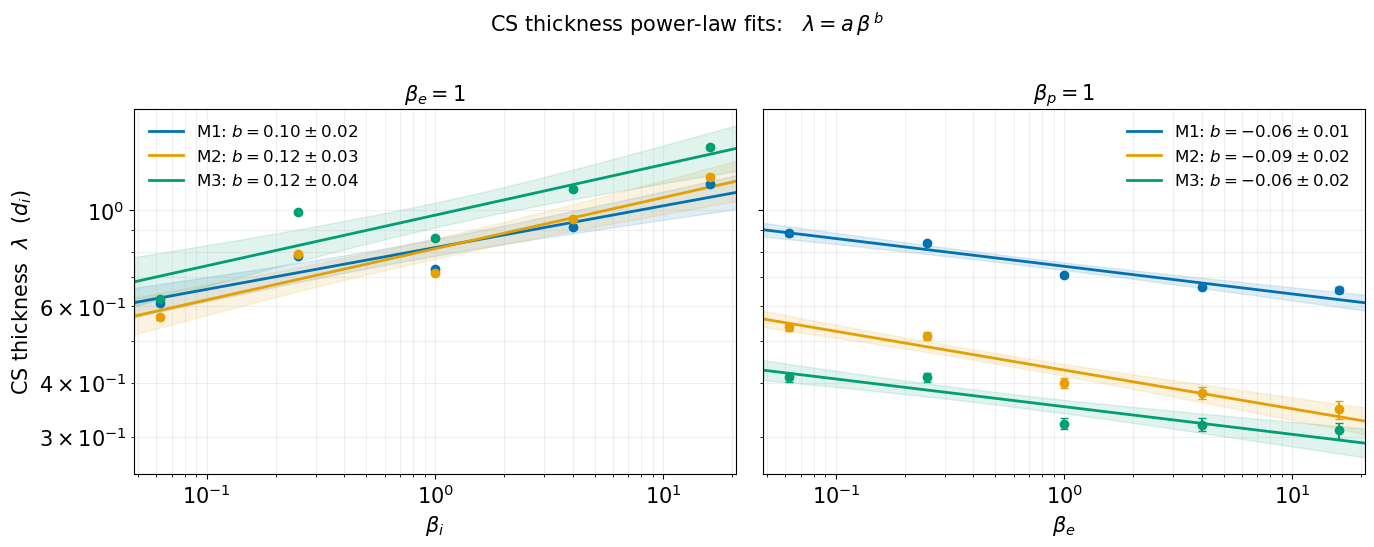


=== beta_i scan (CSV1, beta_e=1) ===
method         a       b    b_se            b 68% CI     R2  rms_log  weighted   n
----------------------------------------------------------------------------------
M1        0.8205   0.096   0.024      [0.073, 0.120]  0.881   0.0737      True   5
M2        0.8156   0.118   0.029      [0.090, 0.147]  0.879   0.0884      True   5
M3        0.9746   0.117   0.036      [0.082, 0.152]  0.826   0.1124      True   5

=== beta_e scan (CSV2, beta_p=1) ===
method         a       b    b_se            b 68% CI     R2  rms_log  weighted   n
----------------------------------------------------------------------------------
M1        0.7428  -0.064   0.011    [-0.075, -0.053]  0.914   0.0361      True   5
M2        0.4278  -0.089   0.017    [-0.106, -0.073]  0.931   0.0452      True   5
M3        0.3522  -0.064   0.019    [-0.082, -0.045]  0.808   0.0562      True   5

Figure -> cs_lambda_vs_beta_two_panels.png
Table  -> powerlaw_fits_by_method.csv


In [12]:
import csv
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 12,
    'figure.titlesize': 15
})

# ======================================================================
# SETTINGS
# ======================================================================
# Two pooled_summary.csv files, same format as before (columns include
# beta, method, VALUE_COL, ERR_COL). In each file the "beta" column is the
# parameter being SCANNED in that panel.
CSV1_PATH = str(RESULTS / "cs_thickness_pooled_1/pooled_summary.csv")     # LEFT  panel: proton/ion beta scan (beta_e = 1 fixed)
CSV2_PATH = str(RESULTS / "cs_thickness_pooled/pooled_summary.csv")     # RIGHT panel: electron beta scan   (beta_p = 1 fixed)

VALUE_COL = "median_lognorm_di"     # per-(beta,method) value to fit  ->  lambda
ERR_COL   = "median_se_di"          # 1-sigma on the value; set "" to force unweighted
METHODS   = ["M1", "M2", "M3"]
YLABEL    = r"CS thickness  $\lambda$  $(d_i)$"
SHOW_BANDS = True
SHAREY     = True        # True -> identical y-axis on both (fairer flat-vs-sloped view)
N_MC       = 10000
OUT_FIG    = str(RESULTS / "cs_lambda_vs_beta_two_panels.png")
OUT_TABLE  = str(RESULTS / "powerlaw_fits_by_method.csv")

# method colours (match the thickness-comparison figure)
COLORS = {"M1": "#0072B2", "M2": "#E69F00", "M3": "#009E73"}

# per-panel headings / axis labels
LEFT_TITLE   = r"$\beta_e = 1$"     # left: electron beta held fixed
RIGHT_TITLE  = r"$\beta_p = 1$"     # right: proton beta held fixed
LEFT_XLABEL  = r"$\beta_i$"         # left x-axis: ion (proton) beta varies
RIGHT_XLABEL = r"$\beta_e$"         # right x-axis: electron beta varies
SUPTITLE     = r"CS thickness power-law fits:   $\lambda = a\,\beta^{\,b}$"


# ======================================================================
# READ a pooled_summary.csv  ->  {method: {beta, y, sy}}
# ======================================================================
def read_summary(csv_path):
    data = defaultdict(lambda: {"beta": [], "y": [], "sy": []})
    with open(csv_path) as f:
        for row in csv.DictReader(f):
            m = row.get("method")
            if m not in METHODS:
                continue
            try:
                beta = float(row["beta"]); y = float(row[VALUE_COL])
            except (KeyError, ValueError):
                continue
            if not np.isfinite(y) or y <= 0:
                continue
            sy = np.nan
            if ERR_COL and row.get(ERR_COL, "") not in ("", "nan", "NaN"):
                try:
                    sy = float(row[ERR_COL])
                except ValueError:
                    sy = np.nan
            data[m]["beta"].append(beta); data[m]["y"].append(y); data[m]["sy"].append(sy)
    return data


# ======================================================================
# Weighted power-law fit (c = 0)  +  Monte-Carlo exponent/band
#   log y = log a + b log beta ; weight 1/sigma_logy with sigma_logy = sy/y.
#   If any SE is missing, falls back to an unweighted (residual-based) fit.
# ======================================================================
def fit_powerlaw(beta, y, sy, xgrid, n_mc=N_MC, rng=None):
    beta, y, sy = map(lambda v: np.asarray(v, float), (beta, y, sy))
    order = np.argsort(beta)
    beta, y, sy = beta[order], y[order], sy[order]
    logx, logy = np.log(beta), np.log(y)
    n = len(beta); dof = max(n - 2, 1)
    rng = rng or np.random.default_rng(0)

    weighted = np.all(np.isfinite(sy)) and np.all(sy > 0)
    if weighted:
        sig_ly = sy / y
        w = 1.0 / sig_ly
        # cov=True (SCALED): the point errors act only as RELATIVE weights; the
        # absolute error on b is set by the scatter of the points about the fit,
        # i.e. it reflects how good the fit is (reduced-chi2 normalised to 1).
        coeffs, cov = np.polyfit(logx, logy, 1, w=w, cov=True)
    else:
        w = None
        coeffs, cov = np.polyfit(logx, logy, 1, cov=True)   # residual-(scatter-)based

    b, log_a = coeffs
    a = float(np.exp(log_a))
    b_se = float(np.sqrt(cov[0, 0]))            # scatter-based -> reflects fit quality
    resid = logy - (log_a + b * logx)

    # fit-quality metrics
    ss_res = float(np.sum(resid ** 2))
    ss_tot = float(np.sum((logy - logy.mean()) ** 2))
    r2 = float(1.0 - ss_res / ss_tot) if ss_tot > 0 else np.nan   # variance explained
    rms_log = float(np.sqrt(ss_res / n))        # RMS residual in log space

    # Monte-Carlo noise made CONSISTENT with the scatter-based error, so the CI /
    # band track the fit quality too (not the tiny input error bars).
    if weighted:
        chi2_red = float(np.sum((resid / sig_ly) ** 2) / dof)
        noise = sig_ly * np.sqrt(chi2_red)      # inflate relative errors up to the scatter
    else:
        noise = np.full(n, np.sqrt(ss_res / dof))
        chi2_red = np.nan

    bs = np.empty(n_mc)
    curves = np.empty((n_mc, xgrid.size))
    for i in range(n_mc):
        logy_i = logy + rng.normal(0.0, noise)
        if weighted:
            bi, log_ai = np.polyfit(logx, logy_i, 1, w=w)
        else:
            bi, log_ai = np.polyfit(logx, logy_i, 1)
        bs[i] = bi
        curves[i] = np.exp(log_ai) * xgrid ** bi
    b_med = float(np.median(bs)); b_lo, b_hi = np.percentile(bs, [16, 84])
    band_lo, band_hi = np.percentile(curves, [16, 84], axis=0)

    return {"a": a, "b": float(b), "b_se": b_se, "b_med": b_med,
            "b_lo": float(b_lo), "b_hi": float(b_hi), "chi2_red": chi2_red,
            "r2": r2, "rms_log": rms_log,
            "weighted": bool(weighted), "n": n, "beta": beta, "y": y, "sy": sy,
            "band_lo": band_lo, "band_hi": band_hi}


# ======================================================================
# Fit every method for one CSV and draw it on one axis
# ======================================================================
def plot_panel(ax, data, xgrid, title, xlabel, ylabel=None):
    fits = {}
    for m in METHODS:
        d = data[m]
        if len(d["beta"]) < 3:
            print(f"[{title}] {m}: only {len(d['beta'])} point(s) -> skipping (need >=3)")
            continue
        res = fit_powerlaw(d["beta"], d["y"], d["sy"], xgrid)
        fits[m] = res
        c = COLORS.get(m)
        if SHOW_BANDS:
            ax.fill_between(xgrid, res["band_lo"], res["band_hi"], color=c, alpha=0.12)
        ax.plot(xgrid, res["a"] * xgrid ** res["b"], "-", color=c, lw=2,
                label=fr"{m}: $b={res['b_med']:.2f}\pm{res['b_se']:.2f}$")
        if np.all(np.isfinite(res["sy"])):
            ax.errorbar(res["beta"], res["y"], yerr=res["sy"], fmt="o", color=c,
                        ms=6, capsize=3, lw=1.4)
        else:
            ax.plot(res["beta"], res["y"], "o", color=c, ms=6)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(xgrid.min(), xgrid.max())     # same x-range on both panels
    ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False)
    ax.grid(True, which="both", alpha=0.2)
    return fits


# ======================================================================
# MAIN
# ======================================================================
data_L = read_summary(CSV1_PATH)
data_R = read_summary(CSV2_PATH)

# common x-range from BOTH files -> identical x-axis extent on both panels
all_beta = np.array([b for d in (data_L, data_R) for m in METHODS for b in d[m]["beta"]], float)
if all_beta.size == 0:
    raise SystemExit("No usable rows found in either CSV (check paths / columns).")
xgrid = np.logspace(np.log10(all_beta.min() / 1.3), np.log10(all_beta.max() * 1.3), 200)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=SHAREY)
fits_L = plot_panel(axL, data_L, xgrid, LEFT_TITLE,  LEFT_XLABEL,  ylabel=YLABEL)
fits_R = plot_panel(axR, data_R, xgrid, RIGHT_TITLE, RIGHT_XLABEL,
                    ylabel=(None if SHAREY else YLABEL))

fig.suptitle(SUPTITLE, y=1.00)
fig.tight_layout()
fig.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# Comparison table  (printed + CSV, both scans)
# ======================================================================
def emit(fits, scan_label, writer):
    print(f"\n=== {scan_label} ===")
    print(f"{'method':<7}{'a':>9}{'b':>8}{'b_se':>8}{'b 68% CI':>20}{'R2':>7}{'rms_log':>9}{'weighted':>10}{'n':>4}")
    print("-" * 82)
    for m in METHODS:
        if m not in fits:
            continue
        r = fits[m]
        ci = f"[{r['b_lo']:.3f}, {r['b_hi']:.3f}]"
        print(f"{m:<7}{r['a']:>9.4f}{r['b_med']:>8.3f}{r['b_se']:>8.3f}{ci:>20}"
              f"{r['r2']:>7.3f}{r['rms_log']:>9.4f}{str(r['weighted']):>10}{r['n']:>4}")
        writer.writerow([scan_label, m, r["a"], r["b_med"], r["b_se"], r["b_lo"], r["b_hi"],
                         r["r2"], r["rms_log"], r["weighted"], r["n"]])

with open(OUT_TABLE, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["scan", "method", "a", "b", "b_se", "b_ci_lo", "b_ci_hi", "r2", "rms_log", "weighted", "n_points"])
    emit(fits_L, "beta_i scan (CSV1, beta_e=1)", w)
    emit(fits_R, "beta_e scan (CSV2, beta_p=1)", w)

print(f"\nFigure -> {OUT_FIG}\nTable  -> {OUT_TABLE}")